# Exploratory Data Analysis (EDA)

## Project: E-commerce Sales Analysis (2024–2025)

### Objective
Explore the integrated e-commerce dataset to understand sales performance, customer behaviour, product performance, and business trends.

### Key Activities
1. Load and understand the integrated dataset.
2. Examine numerical and categorical variables.
3. Analyse order statuses and sales distribution.
4. Explore yearly and monthly sales patterns.
5. Analyse product and category performance.
6. Investigate customer and geographical patterns.
7. Identify meaningful business insights.

### Business Goal
Prepare an evidence-based analysis comparing 2024 and 2025 performance and identify opportunities to improve sales, customer experience, and business profitability.

### Source
`data/cleaned/ecommerce_integrated.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load the integrated dataset
df = pd.read_csv(
    "../data/cleaned/ecommerce_integrated.csv",
    parse_dates=["order_date", "signup_date"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (15608, 24)


In [3]:
#understand the dataset
display(df.head())

,order_id,product_id,quantity,unit_price,discount_amount,price_was_missing,customer_id,order_date,status,payment_method,...,list_price,unit_cost,signup_date,state,acquisition_channel,year,month,year_month,gross_amount,net_amount
0,100001,1031,1,38.99,0.0,False,1530,2024-01-01 09:24:45,completed,credit_card,...,38.99,20.19,2023-12-30,AZ,organic_search,2024,1,2024-01,38.99,38.99
1,100002,1087,1,45.99,0.0,False,3531,2024-01-01 10:37:49,completed,credit_card,...,45.99,20.30,2023-11-19,VA,organic_search,2024,1,2024-01,45.99,45.99
2,100002,1072,1,141.99,0.0,False,3531,2024-01-01 10:37:49,completed,credit_card,...,141.99,62.78,2023-11-19,VA,organic_search,2024,1,2024-01,141.99,141.99
3,100003,1048,1,139.99,0.0,False,840,2024-01-01 10:59:09,completed,credit_card,...,139.99,71.41,2023-10-30,MN,organic_search,2024,1,2024-01,139.99,139.99
4,100004,1083,1,19.99,2.0,False,725,2024-01-01 12:48:34,completed,apple_pay,...,19.99,9.51,2023-08-20,MI,paid_search,2024,1,2024-01,19.99,17.99


In [4]:
#stastical summary
display(df.describe().round(2))

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,shipping_fee,list_price,unit_cost,signup_date,year,month,gross_amount,net_amount
count,15608.00,15608.00,15608.00,15608.00,15608.00,15608.00,15608,15608.00,15608.00,15608.00,15608,15608.00,15608.00,15608.00,15608.00
mean,104570.43,1046.47,1.24,113.11,3.20,1791.01,2025-01-29 00:02:44.918247168,0.97,110.17,56.25,2024-08-20 04:29:51.696565504,2024.54,6.99,136.14,132.93
min,100001.00,1001.00,1.00,7.99,0.00,2.00,2024-01-01 09:24:45,0.00,7.99,4.76,2023-06-20 00:00:00,2024.00,1.00,7.99,6.39
25%,102269.75,1020.00,1.00,49.99,0.00,870.00,2024-08-04 18:06:29,0.00,49.99,23.39,2024-02-25 00:00:00,2024.00,4.00,54.58,53.54
50%,104554.50,1048.00,1.00,86.09,0.00,1813.00,2025-02-02 09:25:21.500000,0.00,85.99,43.62,2024-08-05 00:00:00,2025.00,7.00,97.99,96.99
75%,106867.25,1073.00,1.00,141.74,0.00,2741.00,2025-08-02 15:25:03.750000128,0.00,135.99,67.46,2025-01-28 00:00:00,2025.00,10.00,160.64,154.34
max,109207.00,1090.00,4.00,812.69,196.56,3600.00,2025-12-31 23:23:29,6.95,773.99,445.47,2025-12-17 00:00:00,2025.00,12.00,1965.56,1871.96
std,2659.67,28.28,0.58,108.76,11.15,1066.29,NaN,2.41,105.91,58.55,NaN,0.50,3.52,134.39,132.17


In [5]:
# Examine categorical columns
display(df.describe(include="object"))

,status,payment_method,discount_code,product_name,category,state,acquisition_channel,year_month
count,15608,15608,2378,15608,15608,15608,15608,15608
unique,3,4,3,90,8,35,6,24
top,completed,credit_card,HOLIDAY20,Nordic Ornament Set,Kitchen,CA,organic_search,2025-11
freq,14283,8929,1327,286,3195,2141,6327,1151


### Categorical Data Exploration – Key Observations

1. **Order Status:** Completed orders account for the majority of product-line records, followed by returned and canceled orders.
2. **Payment Methods:** Credit card is the most frequently used payment method, while gift cards are the least frequently used.
3. **Product Categories:** Kitchen and Decor have the highest number of product-line records. Furniture has the lowest.
4. **Customer Acquisition:** Organic search is the most frequently represented acquisition channel. Affiliate is the least represented.
5. **Geographical Distribution:** The dataset contains customers from 35 states, with California having the highest number of product-line records.
6. **Dataset Coverage:** The integrated dataset contains 9,207 unique orders, 90 products, and 2,106 unique purchasing customers.

**Important Note:** These observations are based on product-line records unless otherwise specified. Product-line frequency should not be interpreted as revenue, unique customer count, or order count.

In [6]:
categorical_columns = [
    "status",
    "payment_method",
    "category",
    "acquisition_channel",
    "state"
]

for col in categorical_columns:
    print(f"\n--- {col.upper()} ---")
    print(df[col].value_counts())


--- STATUS ---
status
completed    14283
returned       766
canceled       559
Name: count, dtype: int64

--- PAYMENT_METHOD ---
payment_method
credit_card    8929
paypal         3387
apple_pay      2363
gift_card       929
Name: count, dtype: int64

--- CATEGORY ---
category
Kitchen      3195
Decor        3073
Bedding      1932
Storage      1852
Bath         1740
Outdoor      1476
Lighting     1295
Furniture    1045
Name: count, dtype: int64

--- ACQUISITION_CHANNEL ---
acquisition_channel
organic_search    6327
paid_search       2391
referral          2306
email             2131
paid_social       1911
affiliate          542
Name: count, dtype: int64

--- STATE ---
state
CA    2141
NY    1286
TX    1262
FL    1136
PA     706
MI     674
IL     610
VA     603
GA     529
OH     525
NC     509
CO     459
NJ     407
AZ     372
SC     364
CT     344
IN     339
MA     290
WA     281
LA     276
WI     263
AL     246
MD     242
TN     234
MO     218
NV     197
MN     190
OK     185
UT     180

In [7]:
print("Unique orders:", df["order_id"].nunique())
print("Unique products:", df["product_id"].nunique())
print("Unique customers:", df["customer_id"].nunique())
print("Unique categories:", df["category"].nunique())
print("Unique states:", df["state"].nunique())

Unique orders: 9207
Unique products: 90
Unique customers: 2106
Unique categories: 8
Unique states: 35


In [8]:
# Create a dataset containing only completed orders
sales_df = df[df["status"] == "completed"].copy()

# Check the result
print("Original dataset shape:", df.shape)
print("Completed sales dataset shape:", sales_df.shape)

print("\nOrder status in sales dataset:")
print(sales_df["status"].value_counts())

print("\nUnique completed orders:", sales_df["order_id"].nunique())

Original dataset shape: (15608, 24)
Completed sales dataset shape: (14283, 24)

Order status in sales dataset:
status
completed    14283
Name: count, dtype: int64

Unique completed orders: 8456


In [9]:
# Calculate total completed-order merchandise revenue

total_revenue = sales_df["net_amount"].sum()

print("Total Net Merchandise Revenue:", round(total_revenue, 2))

Total Net Merchandise Revenue: 1881974.28


In [10]:
# Group revenue by year

yearly_revenue = (
    sales_df.groupby("year")["net_amount"]
    .sum()
    .reset_index()
)

yearly_revenue.columns = ["Year", "Net Revenue"]

yearly_revenue["Net Revenue"] = yearly_revenue["Net Revenue"].round(2)

display(yearly_revenue)

,Year,Net Revenue
0,2024,850786.45
1,2025,1031187.83


In [11]:
# Calculate year-over-year revenue growth

revenue_2024 = yearly_revenue.loc[
    yearly_revenue["Year"] == 2024, "Net Revenue"
].iloc[0]

revenue_2025 = yearly_revenue.loc[
    yearly_revenue["Year"] == 2025, "Net Revenue"
].iloc[0]

growth = ((revenue_2025 - revenue_2024) / revenue_2024) * 100

print(f"2024 Revenue: ${revenue_2024:,.2f}")
print(f"2025 Revenue: ${revenue_2025:,.2f}")
print(f"Year-over-Year Revenue Growth: {growth:.2f}%")

2024 Revenue: $850,786.45
2025 Revenue: $1,031,187.83
Year-over-Year Revenue Growth: 21.20%


### Monthly Revenue Analysis – Key Findings

1. **Consistent Growth:** All 12 months in 2025 generated higher net merchandise revenue than the corresponding months in 2024.
2. **Strongest Month:** November recorded the highest revenue in both years, reaching $100,587.34 in 2024 and $130,083.83 in 2025.
3. **Highest Growth:** August recorded the highest year-over-year growth at 46.05%.
4. **Slowest Growth:** December recorded the lowest year-over-year growth at 5.08%.
5. **Overall Trend:** The business demonstrated positive revenue growth throughout 2025 compared with 2024.

**Business Interpretation:** The consistent year-over-year improvement suggests stronger sales performance in 2025. November's recurring revenue peak may indicate seasonality or promotional effects, which require further investigation.

In [12]:
# Calculate monthly net merchandise revenue

monthly_revenue = (
    sales_df.groupby("year_month")["net_amount"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["Year-Month", "Net Revenue"]

monthly_revenue["Net Revenue"] = monthly_revenue["Net Revenue"].round(2)

display(monthly_revenue)

,Year-Month,Net Revenue
0,2024-01,54389.51
1,2024-02,63274.62
2,2024-03,71769.38
3,2024-04,64768.74
4,2024-05,73652.84
5,2024-06,67205.38
6,2024-07,77269.04
7,2024-08,62683.57
8,2024-09,60054.02
9,2024-10,68387.83


In [13]:
# Extract month number and year

monthly_comparison = sales_df.pivot_table(
    index="month",
    columns="year",
    values="net_amount",
    aggfunc="sum"
)

monthly_comparison.columns = ["2024 Revenue", "2025 Revenue"]

monthly_comparison["Revenue Difference"] = (
    monthly_comparison["2025 Revenue"] -
    monthly_comparison["2024 Revenue"]
)

monthly_comparison["Growth (%)"] = (
    monthly_comparison["Revenue Difference"] /
    monthly_comparison["2024 Revenue"]
) * 100

display(monthly_comparison.round(2))

,2024 Revenue,2025 Revenue,Revenue Difference,Growth (%)
month,,,,
1,54389.51,73067.47,18677.96,34.34
2,63274.62,70490.14,7215.52,11.40
3,71769.38,78763.91,6994.53,9.75
4,64768.74,79926.95,15158.21,23.40
5,73652.84,83178.81,9525.97,12.93
6,67205.38,92311.17,25105.79,37.36
7,77269.04,83428.29,6159.25,7.97
8,62683.57,91547.36,28863.79,46.05
9,60054.02,75215.77,15161.75,25.25


### Product Category Revenue Analysis – Key Findings

1. **Top Performing Category:** Furniture generated the highest net merchandise revenue of $322,848.81, contributing 17.15% of total revenue.
2. **Strong Categories:** Kitchen and Decor generated $279,831.16 and $277,961.15 respectively.
3. **Lowest Performing Category:** Bath generated the lowest net merchandise revenue of $109,024.59, contributing 5.79%.
4. **Interesting Observation:** Furniture had the lowest number of product-line records in the earlier category frequency analysis but generated the highest revenue. This suggests that sales volume alone does not determine revenue performance.

**Business Interpretation:** Furniture is the leading revenue-generating category, while Bath contributes the least. Further analysis of quantity sold, average selling prices, profitability and returns is required before making category-level business recommendations.

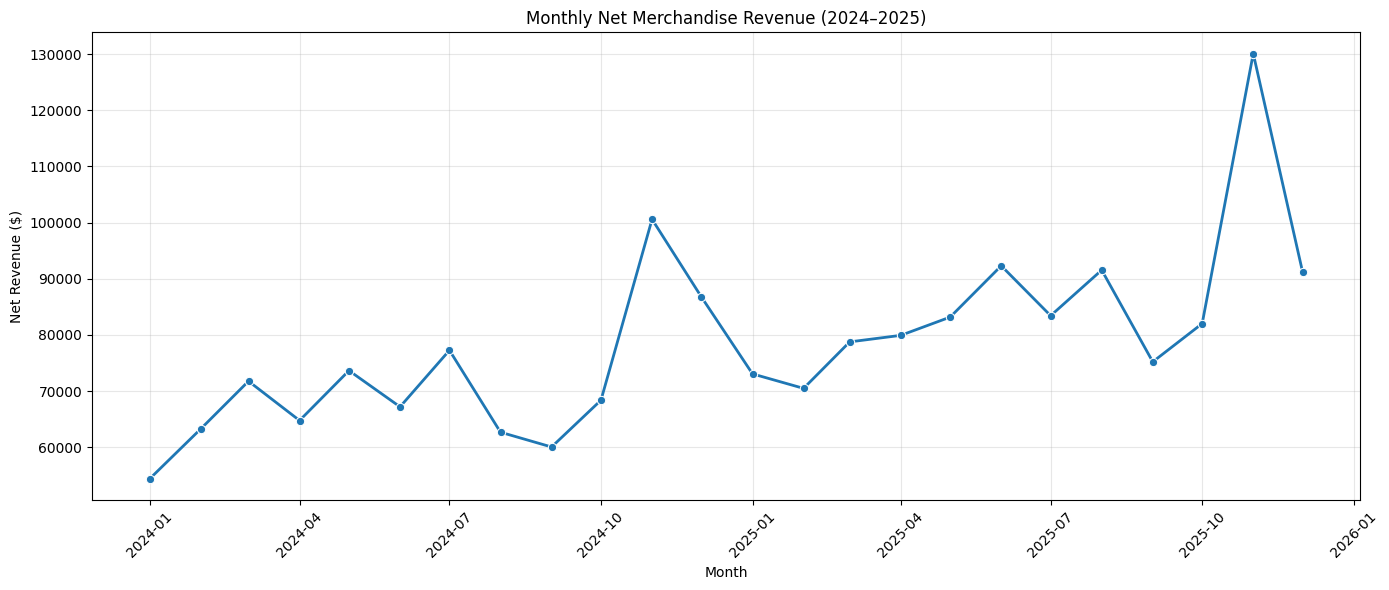

In [14]:
# Prepare monthly revenue data for visualization

monthly_revenue["Date"] = pd.to_datetime(
    monthly_revenue["Year-Month"]
)

# Create monthly revenue trend chart

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="Date",
    y="Net Revenue",
    marker="o",
    linewidth=2
)

plt.title("Monthly Net Merchandise Revenue (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Net Revenue ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [15]:
# Calculate net merchandise revenue by product category

category_revenue = (
    sales_df.groupby("category")["net_amount"]
    .sum()
    .reset_index()
)

# Sort categories from highest to lowest revenue

category_revenue = category_revenue.sort_values(
    by="net_amount",
    ascending=False
)

category_revenue.columns = ["Category", "Net Revenue"]

category_revenue["Net Revenue"] = (
    category_revenue["Net Revenue"].round(2)
)

display(category_revenue)

,Category,Net Revenue
3,Furniture,322848.81
4,Kitchen,279831.16
2,Decor,277961.15
1,Bedding,267025.16
6,Outdoor,247750.78
5,Lighting,237847.68
7,Storage,139684.95
0,Bath,109024.59


In [16]:
# Calculate category contribution percentage

category_revenue["Revenue Contribution (%)"] = (
    category_revenue["Net Revenue"] / total_revenue
) * 100

category_revenue["Revenue Contribution (%)"] = (
    category_revenue["Revenue Contribution (%)"].round(2)
)

display(category_revenue)

,Category,Net Revenue,Revenue Contribution (%)
3,Furniture,322848.81,17.15
4,Kitchen,279831.16,14.87
2,Decor,277961.15,14.77
1,Bedding,267025.16,14.19
6,Outdoor,247750.78,13.16
5,Lighting,237847.68,12.64
7,Storage,139684.95,7.42
0,Bath,109024.59,5.79


### Year-over-Year Category Revenue Analysis – Key Findings

1. **Consistent Growth:** All eight product categories recorded positive revenue growth in 2025 compared with 2024.
2. **Revenue Leader:** Furniture generated the highest 2025 revenue of $178,496.47 and the largest absolute revenue increase of $34,144.13.
3. **Fastest Growing Category:** Storage recorded the highest growth rate of 40.83%, increasing from $58,000.43 to $81,684.52.
4. **Slowest Growing Category:** Outdoor recorded the lowest growth rate of 11.38%, although its revenue still increased.
5. **Strong Kitchen Performance:** Kitchen achieved 26.26% growth and generated the second-highest revenue in 2025.

**Business Interpretation:** Furniture continues to be the leading revenue contributor, while Storage represents a high-growth opportunity. Outdoor deserves further investigation because its growth was slower than the overall business growth rate.

In [17]:
# Compare category revenue across 2024 and 2025

category_yearly = sales_df.pivot_table(
    index="category",
    columns="year",
    values="net_amount",
    aggfunc="sum"
)

category_yearly.columns = ["2024 Revenue", "2025 Revenue"]

# Calculate revenue difference
category_yearly["Revenue Difference"] = (
    category_yearly["2025 Revenue"] -
    category_yearly["2024 Revenue"]
)

# Calculate year-over-year growth
category_yearly["Growth (%)"] = (
    category_yearly["Revenue Difference"] /
    category_yearly["2024 Revenue"]
) * 100

# Sort by 2025 revenue
category_yearly = category_yearly.sort_values(
    by="2025 Revenue",
    ascending=False
)

display(category_yearly.round(2))

,2024 Revenue,2025 Revenue,Revenue Difference,Growth (%)
category,,,,
Furniture,144352.34,178496.47,34144.13,23.65
Kitchen,123677.50,156153.66,32476.16,26.26
Decor,127140.17,150820.98,23680.81,18.63
Bedding,123827.76,143197.40,19369.64,15.64
Lighting,106184.05,131663.63,25479.58,24.00
Outdoor,117207.10,130543.68,13336.58,11.38
Storage,58000.43,81684.52,23684.09,40.83
Bath,50397.10,58627.49,8230.39,16.33


### Top 10 Product Performance – Key Findings

1. **Top Revenue-Generating Product:** Cotton Patio Chair (Outdoor) generated the highest net merchandise revenue of $67,034.90.
2. **Furniture Representation:** Furniture contributed four products to the top 10 list, making it the most represented category.
3. **Decor Representation:** Decor contributed three products to the top 10 list.
4. **Interesting Observation:** Although Furniture generated the highest overall category revenue, the highest-revenue individual product belongs to Outdoor.
5. **Revenue Concentration:** The top 10 products collectively generated $443,579.85, representing approximately 23.57% of total completed-order merchandise revenue.

**Business Interpretation:** A small group of products contributes a significant share of business revenue. These products deserve attention when planning inventory, marketing and product availability.

In [18]:
# Calculate net merchandise revenue by product

product_revenue = (
    sales_df.groupby(
        ["product_id", "product_name", "category"]
    )["net_amount"]
    .sum()
    .reset_index()
)

# Sort products by revenue

product_revenue = product_revenue.sort_values(
    by="net_amount",
    ascending=False
)

product_revenue.columns = [
    "Product ID",
    "Product Name",
    "Category",
    "Net Revenue"
]

display(product_revenue.head(10))

,Product ID,Product Name,Category,Net Revenue
58,1059,Cotton Patio Chair,Outdoor,67034.90
41,1042,Classic Dining Chair Pair,Furniture,52017.94
71,1072,Coastal Picture Frame Set,Decor,44228.16
17,1018,Ceramic Quilt,Bedding,41400.47
43,1044,Bamboo Nightstand,Furniture,41365.73
75,1076,Modern Wreath,Decor,41022.95
40,1041,Nordic Side Table,Furniture,40394.19
53,1054,Velvet String Lights,Lighting,38838.42
79,1080,Classic Garland,Decor,38681.43
39,1040,Marble Bookshelf,Furniture,38595.66


### Bottom 10 Product Performance – Key Findings

1. **Lowest Revenue Product:** Matte Black Shower Curtain generated the lowest net merchandise revenue of $1,475.47.
2. **Bath Category:** Three Bath products appeared in the bottom 10, consistent with Bath's position as the lowest-revenue category.
3. **Storage Category:** Three Storage products appeared in the bottom 10, despite Storage having the highest year-over-year category growth rate of 40.83%.
4. **Revenue Contribution:** The bottom 10 products collectively generated $43,881.55, representing approximately 2.33% of total completed-order merchandise revenue.

**Business Interpretation:** Some individual products generate relatively low revenue even within growing categories. These products should be investigated further before making decisions about pricing, marketing, inventory or discontinuation.

In [19]:
# Identify the 10 lowest revenue-generating products

bottom_10_products = product_revenue.sort_values(
    by="Net Revenue",
    ascending=True
).head(10)

display(bottom_10_products)

,Product ID,Product Name,Category,Net Revenue
29,1030,Matte Black Shower Curtain,Bath,1475.47
70,1071,Oak Vase,Decor,3062.83
68,1069,Bamboo Umbrella Stand,Outdoor,3790.64
5,1006,Walnut Coffee Grinder,Kitchen,4518.83
89,1090,Bamboo Laundry Basket,Storage,4547.63
87,1088,Coastal Coat Rack,Storage,4822.26
82,1083,Velvet Drawer Organizer,Storage,5075.29
28,1029,Cotton Bath Mat,Bath,5198.45
36,1037,Coastal Waffle Towel Set,Bath,5532.83
2,1003,Matte Black Dutch Oven,Kitchen,5857.32


### Bottom 10 Product Sales Volume Analysis – Key Findings

1. **Low Revenue Per Unit:** Oak Vase generated an average net revenue of $10.01 per unit despite selling 306 units.
2. **Lowest Average Revenue Per Unit:** Matte Black Shower Curtain recorded $7.93 per unit and generated the lowest total revenue in the bottom 10.
3. **Lowest Sales Volume:** Bamboo Umbrella Stand recorded the lowest quantity sold, with 139 units across 113 orders.
4. **Higher Revenue Per Unit:** Cotton Bath Mat generated an average net revenue of $31.13 per unit, the highest among the bottom 10 products.
5. **Different Performance Patterns:** Low product revenue can be associated with lower sales volume, lower revenue per unit, or a combination of both.

**Business Interpretation:** Product performance should be evaluated using revenue, units sold, order frequency and average revenue per unit rather than revenue alone. Further investigation is needed before making pricing, marketing or inventory decisions.

In [20]:
# Identify the bottom 10 product IDs

bottom_product_ids = bottom_10_products["Product ID"].tolist()

# Analyse their sales volume and revenue

bottom_product_analysis = (
    sales_df[sales_df["product_id"].isin(bottom_product_ids)]
    .groupby(["product_id", "product_name", "category"])
    .agg(
        Units_Sold=("quantity", "sum"),
        Number_of_Orders=("order_id", "nunique"),
        Net_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

# Calculate average net revenue per unit

bottom_product_analysis["Avg_Revenue_Per_Unit"] = (
    bottom_product_analysis["Net_Revenue"] /
    bottom_product_analysis["Units_Sold"]
)

# Sort by net revenue

bottom_product_analysis = bottom_product_analysis.sort_values(
    by="Net_Revenue",
    ascending=True
)

display(bottom_product_analysis.round(2))

,product_id,product_name,category,Units_Sold,Number_of_Orders,Net_Revenue,Avg_Revenue_Per_Unit
3,1030,Matte Black Shower Curtain,Bath,186,141,1475.47,7.93
6,1071,Oak Vase,Decor,306,240,3062.83,10.01
5,1069,Bamboo Umbrella Stand,Outdoor,139,113,3790.64,27.27
1,1006,Walnut Coffee Grinder,Kitchen,265,212,4518.83,17.05
9,1090,Bamboo Laundry Basket,Storage,252,200,4547.63,18.05
8,1088,Coastal Coat Rack,Storage,228,183,4822.26,21.15
7,1083,Velvet Drawer Organizer,Storage,252,193,5075.29,20.14
2,1029,Cotton Bath Mat,Bath,167,135,5198.45,31.13
4,1037,Coastal Waffle Towel Set,Bath,191,159,5532.83,28.97
0,1003,Matte Black Dutch Oven,Kitchen,256,199,5857.32,22.88


### Overall Gross Profit Analysis – Key Findings

1. **Total Net Merchandise Revenue:** $1,881,974.28.
2. **Total Product Cost:** $956,026.02.
3. **Estimated Gross Profit:** $925,948.26.
4. **Estimated Gross Profit Margin:** 49.20%.

**Business Interpretation:** The business retained approximately 49.20% of its net merchandise revenue after deducting the recorded product costs. This represents estimated gross profit, not net profit, because operating expenses and other business costs have not been deducted.

**Limitation:** The calculation assumes the recorded `unit_cost` represents the relevant product cost for each transaction. Historical cost accuracy has not yet been independently verified.

In [21]:
# Calculate product cost for completed sales

sales_df["total_product_cost"] = (
    sales_df["quantity"] * sales_df["unit_cost"]
)

# Calculate gross profit

sales_df["gross_profit"] = (
    sales_df["net_amount"] - sales_df["total_product_cost"]
)

# Calculate gross profit margin

sales_df["gross_profit_margin"] = (
    sales_df["gross_profit"] / sales_df["net_amount"]
) * 100

# Check the results

print("Total Net Revenue:", round(sales_df["net_amount"].sum(), 2))

print("Total Product Cost:", round(sales_df["total_product_cost"].sum(), 2))

print("Total Gross Profit:", round(sales_df["gross_profit"].sum(), 2))

Total Net Revenue: 1881974.28
Total Product Cost: 956026.02
Total Gross Profit: 925948.26


### Bottom 10 Products by Gross Profit

**Objective:** Identify products contributing the least gross profit and evaluate their gross profit margins.

**Key Findings:**

1. Matte Black Shower Curtain generated the lowest gross profit of **$590.11**, with a gross profit margin of 39.99%.
2. Oak Vase generated $1,275.79 gross profit, with a margin of 41.65%.
3. Bamboo Laundry Basket recorded a relatively high gross profit margin of **56.83%**, despite appearing among the bottom 10 products by gross profit.
4. Matte Black Dutch Oven and Walnut Coffee Grinder also recorded relatively low margins of 41.00% and 42.88%.

**Business Interpretation:**

Low gross profit does not always indicate poor product profitability. Some products may generate less total profit because of lower sales revenue while maintaining healthy margins. Products with both low gross profit and low margins may require further investigation into pricing, discounts, product costs, and sales performance.

**Note:** These results are based on completed orders and estimated product costs.

In [22]:
# Calculate profitability by product category

category_profit = (
    sales_df.groupby("category")
    .agg(
        Net_Revenue=("net_amount", "sum"),
        Product_Cost=("total_product_cost", "sum"),
        Gross_Profit=("gross_profit", "sum")
    )
    .reset_index()
)

# Calculate gross profit margin

category_profit["Gross_Profit_Margin (%)"] = (
    category_profit["Gross_Profit"] /
    category_profit["Net_Revenue"]
) * 100

# Sort by gross profit

category_profit = category_profit.sort_values(
    by="Gross_Profit",
    ascending=False
)

display(category_profit.round(2))

,category,Net_Revenue,Product_Cost,Gross_Profit,Gross_Profit_Margin (%)
3,Furniture,322848.81,173793.64,149055.17,46.17
2,Decor,277961.15,135615.07,142346.08,51.21
1,Bedding,267025.16,130362.12,136663.04,51.18
4,Kitchen,279831.16,147408.87,132422.29,47.32
6,Outdoor,247750.78,123976.87,123773.91,49.96
5,Lighting,237847.68,124826.18,113021.50,47.52
7,Storage,139684.95,62031.69,77653.26,55.59
0,Bath,109024.59,58011.58,51013.01,46.79


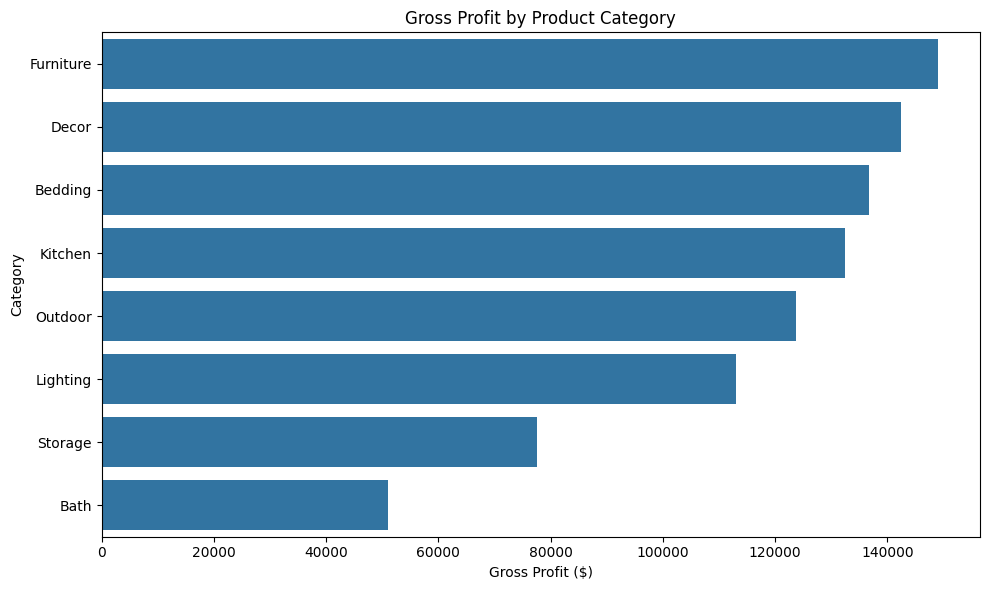

In [23]:
# Visualize gross profit by category

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_profit,
    x="Gross_Profit",
    y="category"
)

plt.title("Gross Profit by Product Category")
plt.xlabel("Gross Profit ($)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

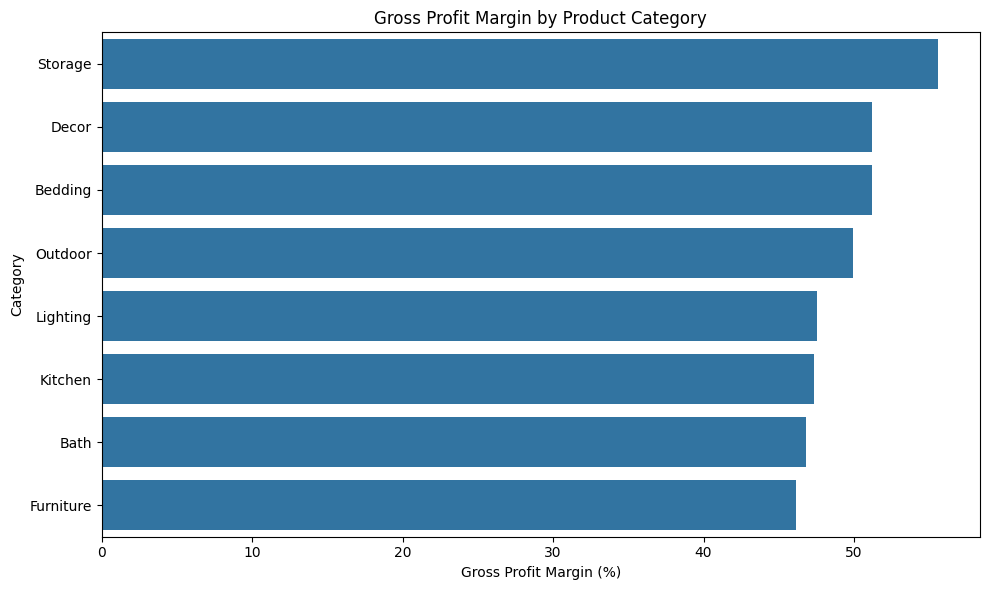

In [27]:
# Visualize gross profit margin by category

category_margin = category_profit.sort_values(
    by="Gross_Profit_Margin (%)",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_margin,
    x="Gross_Profit_Margin (%)",
    y="category"
)

plt.title("Gross Profit Margin by Product Category")
plt.xlabel("Gross Profit Margin (%)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [25]:
product_profit = (
    sales_df.groupby(["product_id", "product_name", "category"])
    .agg(
        Net_Revenue=("net_amount", "sum"),
        Product_Cost=("total_product_cost", "sum"),
        Gross_Profit=("gross_profit", "sum")
    )
    .reset_index()
)

product_profit["Gross_Profit_Margin (%)"] = (
    product_profit["Gross_Profit"] /
    product_profit["Net_Revenue"]
) * 100

top_10_profit_products = product_profit.sort_values(
    by="Gross_Profit",
    ascending=False
).head(10)

display(top_10_profit_products.round(2))

,product_id,product_name,category,Net_Revenue,Product_Cost,Gross_Profit,Gross_Profit_Margin (%)
58,1059,Cotton Patio Chair,Outdoor,67034.90,37036.44,29998.46,44.75
71,1072,Coastal Picture Frame Set,Decor,44228.16,19461.80,24766.36,56.00
40,1041,Nordic Side Table,Furniture,40394.19,17960.92,22433.27,55.54
41,1042,Classic Dining Chair Pair,Furniture,52017.94,29846.49,22171.45,42.62
53,1054,Velvet String Lights,Lighting,38838.42,16915.92,21922.50,56.45
79,1080,Classic Garland,Decor,38681.43,16879.68,21801.75,56.36
17,1018,Ceramic Quilt,Bedding,41400.47,20195.40,21205.07,51.22
75,1076,Modern Wreath,Decor,41022.95,19968.16,21054.79,51.32
62,1063,Matte Black Hammock,Outdoor,37150.04,16756.50,20393.54,54.90
51,1052,Linen Pendant Light,Lighting,33906.02,14358.06,19547.96,57.65


### Product-Level Gross Profit Margin Analysis

**Objective:** Identify products with the highest and lowest gross profit margins.

**Highest Margin Findings:**

1. Linen Pendant Light recorded the highest gross profit margin at **57.65%**.
2. Coastal Closet System followed closely with 57.62%.
3. Cotton Bath Mat achieved a margin of 57.60%, despite generating relatively low total gross profit.
4. Velvet String Lights generated $21,922.50 gross profit with a margin of 56.45%.

**Lowest Margin Findings:**

1. Brass Chef Knife recorded the lowest gross profit margin at **38.12%**.
2. Classic Decorative Tray and Oak Measuring Cup Set also recorded relatively low margins of 38.71% and 38.82%.
3. Bath appeared four times among the bottom 10 products by margin.
4. Nordic Arc Lamp generated substantial gross profit despite having a relatively low margin of 39.13%.

**Business Interpretation:**

Products with high gross profit margins retain a larger proportion of their net revenue after product costs. However, high margins do not necessarily translate into high total gross profit. Business decisions should consider revenue, gross profit, and gross profit margin together.

**Note:** The analysis uses completed orders and estimated product costs. Gross profit does not include operating expenses or other business costs.

In [28]:
bottom_10_profit_products = product_profit.sort_values(
    by="Gross_Profit",
    ascending=True
).head(10)

display(bottom_10_profit_products.round(2))

,product_id,product_name,category,Net_Revenue,Product_Cost,Gross_Profit,Gross_Profit_Margin (%)
29,1030,Matte Black Shower Curtain,Bath,1475.47,885.36,590.11,39.99
70,1071,Oak Vase,Decor,3062.83,1787.04,1275.79,41.65
68,1069,Bamboo Umbrella Stand,Outdoor,3790.64,1855.65,1934.99,51.05
5,1006,Walnut Coffee Grinder,Kitchen,4518.83,2581.10,1937.73,42.88
87,1088,Coastal Coat Rack,Storage,4822.26,2742.84,2079.42,43.12
2,1003,Matte Black Dutch Oven,Kitchen,5857.32,3456.00,2401.32,41.00
66,1067,Velvet Outdoor Cushion Pair,Outdoor,5984.81,3435.70,2549.11,42.59
89,1090,Bamboo Laundry Basket,Storage,4547.63,1963.08,2584.55,56.83
82,1083,Velvet Drawer Organizer,Storage,5075.29,2396.52,2678.77,52.78
36,1037,Coastal Waffle Towel Set,Bath,5532.83,2731.30,2801.53,50.63


In [29]:
# 10 products with the highest gross profit margins

top_10_margin = product_profit.sort_values(
    by="Gross_Profit_Margin (%)",
    ascending=False
).head(10)

display(top_10_margin.round(2))

,product_id,product_name,category,Net_Revenue,Product_Cost,Gross_Profit,Gross_Profit_Margin (%)
51,1052,Linen Pendant Light,Lighting,33906.02,14358.06,19547.96,57.65
84,1085,Coastal Closet System,Storage,26601.45,11274.60,15326.85,57.62
28,1029,Cotton Bath Mat,Bath,5198.45,2204.40,2994.05,57.60
69,1070,Stoneware Wall Mirror,Decor,31645.35,13452.40,18192.95,57.49
24,1025,Bamboo Bed Skirt,Bedding,26590.69,11426.56,15164.13,57.03
89,1090,Bamboo Laundry Basket,Storage,4547.63,1963.08,2584.55,56.83
7,1008,Matte Black Utensil Set,Kitchen,10964.17,4765.00,6199.17,56.54
53,1054,Velvet String Lights,Lighting,38838.42,16915.92,21922.50,56.45
79,1080,Classic Garland,Decor,38681.43,16879.68,21801.75,56.36
67,1068,Rattan Grill Tool Set,Outdoor,7826.60,3415.72,4410.88,56.36


In [30]:
# 10 products with the lowest gross profit margins

bottom_10_margin = product_profit.sort_values(
    by="Gross_Profit_Margin (%)",
    ascending=True
).head(10)

display(bottom_10_margin.round(2))

,product_id,product_name,category,Net_Revenue,Product_Cost,Gross_Profit,Gross_Profit_Margin (%)
0,1001,Brass Chef Knife,Kitchen,14850.03,9189.33,5660.70,38.12
80,1081,Classic Decorative Tray,Decor,20554.78,12597.96,7956.82,38.71
14,1015,Oak Measuring Cup Set,Kitchen,27055.64,16552.12,10503.52,38.82
32,1033,Walnut Hand Towel Pair,Bath,16544.07,10115.36,6428.71,38.86
31,1032,Linen Bath Robe,Bath,18473.99,11288.71,7185.28,38.89
55,1056,Nordic Arc Lamp,Lighting,37808.04,23014.68,14793.36,39.13
19,1020,Coastal Weighted Blanket,Bedding,10906.31,6592.00,4314.31,39.56
29,1030,Matte Black Shower Curtain,Bath,1475.47,885.36,590.11,39.99
72,1073,Rattan Candle Trio,Decor,21077.64,12525.60,8552.04,40.57
35,1036,Cotton Hamper,Bath,13882.90,8241.48,5641.42,40.64


### Order Volume and Average Order Value Analysis

**Objective:** Understand the relationship between completed order volume, average order value, and revenue growth.

**Key Findings:**

1. The business recorded 3,867 completed orders in 2024 and 4,589 in 2025.
2. Completed orders increased by **18.67%**, representing 722 additional orders.
3. Average Order Value increased from $220.01 in 2024 to $224.71 in 2025, representing growth of approximately **2.14%**.
4. Total net merchandise revenue increased by 21.20% between 2024 and 2025.

**Business Interpretation:**

Revenue growth was accompanied by an increase in completed order volume and a smaller increase in average order value. The increase in completed orders was the larger contributor by growth rate.

**Note:** AOV is calculated using completed-order net merchandise revenue, excluding shipping fees.

In [31]:
# Calculate total revenue per order

order_revenue = (
    sales_df.groupby("order_id")["net_amount"]
    .sum()
)

# Calculate average order value

aov = order_revenue.mean()

print("Total Completed Orders:", order_revenue.count())
print("Total Net Revenue:", order_revenue.sum())
print("Average Order Value:", round(aov, 2))

Total Completed Orders: 8456
Total Net Revenue: 1881974.2799999998
Average Order Value: 222.56


In [32]:
# Calculate yearly revenue per order

yearly_order_revenue = (
    sales_df.groupby(["year", "order_id"])["net_amount"]
    .sum()
    .reset_index()
)

# Calculate yearly AOV

yearly_aov = (
    yearly_order_revenue.groupby("year")["net_amount"]
    .mean()
    .reset_index(name="Average_Order_Value")
)

display(yearly_aov.round(2))

,year,Average_Order_Value
0,2024,220.01
1,2025,224.71


In [33]:
# Count unique completed orders by year

yearly_orders = (
    sales_df.groupby("year")["order_id"]
    .nunique()
    .reset_index(name="Total_Orders")
)

display(yearly_orders)

,year,Total_Orders
0,2024,3867
1,2025,4589


In [34]:
# Calculate year-over-year order growth

orders_2024 = yearly_orders.loc[
    yearly_orders["year"] == 2024, "Total_Orders"
].iloc[0]

orders_2025 = yearly_orders.loc[
    yearly_orders["year"] == 2025, "Total_Orders"
].iloc[0]

order_growth = (
    (orders_2025 - orders_2024) / orders_2024
) * 100

print("Order Growth (%):", round(order_growth, 2))

Order Growth (%): 18.67


### Order Status Analysis

**Objective:** Evaluate the distribution of completed, canceled, and returned orders.

**Key Findings:**

1. The dataset contains 9,207 unique orders.
2. 8,456 orders were completed, representing 91.84% of all orders.
3. 407 orders were returned, representing 4.42%.
4. 344 orders were canceled, representing 3.74%.
5. Returns exceeded cancellations by 63 orders.

**Business Interpretation:**

The business achieved a 91.84% order completion rate. However, returned orders accounted for 4.42% of all orders, slightly exceeding the cancellation rate of 3.74%. The business could investigate the reasons behind returns and cancellations to identify opportunities for improving the customer experience.

**Note:** Return and cancellation rates use all 9,207 unique orders as the denominator. Returned orders are reported separately from canceled orders.

In [35]:
# Count unique orders by status

order_status = (
    df.groupby("status")["order_id"]
    .nunique()
    .reset_index(name="Total_Orders")
)

# Calculate percentage

order_status["Percentage (%)"] = (
    order_status["Total_Orders"] /
    order_status["Total_Orders"].sum()
) * 100

display(order_status.round(2))

,status,Total_Orders,Percentage (%)
0,canceled,344,3.74
1,completed,8456,91.84
2,returned,407,4.42


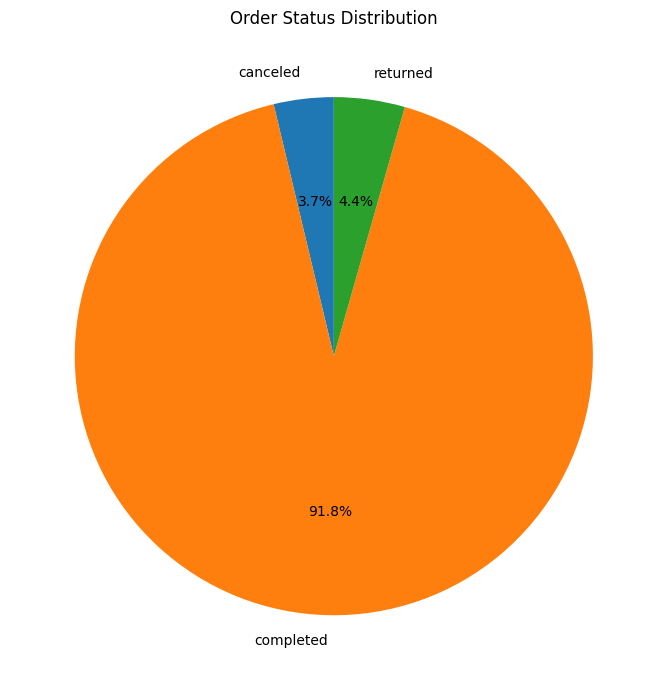

In [36]:
plt.figure(figsize=(7, 7))

plt.pie(
    order_status["Total_Orders"],
    labels=order_status["status"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Status Distribution")

plt.tight_layout()
plt.show()

### Yearly Order Status Analysis

**Objective:** Compare completed, canceled, and returned order percentages between 2024 and 2025.

**Key Findings:**

1. The completion rate increased slightly from 91.81% in 2024 to 91.87% in 2025.
2. The cancellation rate decreased from 3.80% to 3.68%.
3. The return rate increased slightly from 4.39% to 4.44%.
4. Completed orders increased from 3,867 in 2024 to 4,589 in 2025.

**Business Interpretation:**

The business maintained a relatively stable order completion rate across both years. The slight reduction in cancellations is positive, while the small increase in returns may require further monitoring. Since overall order volume increased in 2025, raw cancellation and return counts also increased.

**Note:** Percentages are calculated using the total number of unique orders within each year.

In [37]:
# Count unique orders by year and status

yearly_status = (
    df.groupby(["year", "status"])["order_id"]
    .nunique()
    .reset_index(name="Total_Orders")
)

display(yearly_status)

,year,status,Total_Orders
0,2024,canceled,160
1,2024,completed,3867
2,2024,returned,185
3,2025,canceled,184
4,2025,completed,4589
5,2025,returned,222


In [38]:
# Calculate percentage of each status within each year

yearly_status["Percentage (%)"] = (
    yearly_status["Total_Orders"] /
    yearly_status.groupby("year")["Total_Orders"].transform("sum")
) * 100

display(yearly_status.round(2))

,year,status,Total_Orders,Percentage (%)
0,2024,canceled,160,3.80
1,2024,completed,3867,91.81
2,2024,returned,185,4.39
3,2025,canceled,184,3.68
4,2025,completed,4589,91.87
5,2025,returned,222,4.44


### Payment Method Performance Analysis

The payment method analysis was conducted using completed orders only.

**Key findings:**

- Credit card was the leading payment method, accounting for 4,887 orders and 57.17% of total net merchandise revenue.
- PayPal ranked second, contributing 21.44% of revenue.
- Apple Pay contributed 15.61% of revenue.
- Gift cards had the lowest contribution, accounting for 5.78% of revenue.

**Business interpretation:**

Credit cards are the dominant payment method among completed orders. PayPal and Apple Pay also contribute meaningful shares of revenue, while gift cards account for a relatively small portion.

**Note:** Revenue share measures contribution to total net merchandise revenue. It does not indicate payment-method profitability or customer satisfaction.

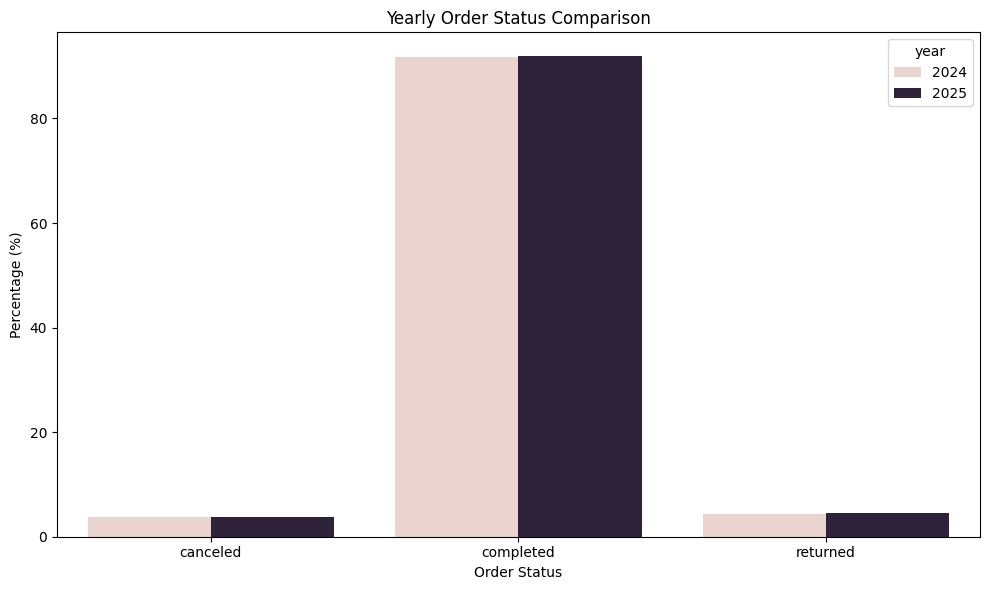

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=yearly_status,
    x="status",
    y="Percentage (%)",
    hue="year"
)

plt.title("Yearly Order Status Comparison")
plt.xlabel("Order Status")
plt.ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

In [41]:
# Count unique orders by payment method

payment_analysis = (
    sales_df.groupby("payment_method")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Net_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

# Calculate revenue contribution percentage

payment_analysis["Revenue_Share (%)"] = (
    payment_analysis["Net_Revenue"] /
    payment_analysis["Net_Revenue"].sum()
) * 100

display(payment_analysis.round(2))

,payment_method,Total_Orders,Net_Revenue,Revenue_Share (%)
0,apple_pay,1311,293821.15,15.61
1,credit_card,4887,1075830.88,57.17
2,gift_card,480,108734.29,5.78
3,paypal,1778,403587.96,21.44


In [42]:
payment_aov = (
    sales_df.groupby("payment_method")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Net_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

payment_aov["AOV"] = (
    payment_aov["Net_Revenue"] /
    payment_aov["Total_Orders"]
)

display(payment_aov.round(2))

,payment_method,Total_Orders,Net_Revenue,AOV
0,apple_pay,1311,293821.15,224.12
1,credit_card,4887,1075830.88,220.14
2,gift_card,480,108734.29,226.53
3,paypal,1778,403587.96,226.99


### Average Order Value (AOV) by Payment Method

AOV was calculated by dividing the net merchandise revenue by the number of unique completed orders for each payment method.

**Key findings:**

- PayPal recorded the highest AOV at $226.99.
- Gift cards followed closely with an AOV of $226.53.
- Apple Pay recorded an AOV of $224.12.
- Credit cards had the lowest AOV at $220.14, despite contributing the highest total revenue.

**Business interpretation:**

Credit cards dominate overall revenue because they have the highest order volume. However, PayPal users recorded the highest average spending per order.

The difference between the highest and lowest AOV is relatively small ($6.85). Therefore, the results show modest differences in average spending across payment methods rather than a major spending gap.

**Note:** These findings show an association between payment method and AOV. They do not establish that the payment method causes customers to spend more or less.

In [43]:
channel_analysis = (
    sales_df.groupby("acquisition_channel")
    .agg(
        Total_Customers=("customer_id", "nunique"),
        Total_Orders=("order_id", "nunique"),
        Net_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

channel_analysis["Revenue_Share (%)"] = (
    channel_analysis["Net_Revenue"] /
    channel_analysis["Net_Revenue"].sum()
) * 100

display(
    channel_analysis
    .sort_values("Net_Revenue", ascending=False)
    .round(2)
)

,acquisition_channel,Total_Customers,Total_Orders,Net_Revenue,Revenue_Share (%)
2,organic_search,741,3458,773610.01,41.11
3,paid_search,327,1261,290406.11,15.43
5,referral,248,1247,274073.91,14.56
1,email,271,1132,241943.34,12.86
4,paid_social,367,1051,238395.85,12.67
0,affiliate,93,307,63545.06,3.38


### Customer Acquisition Channel Performance

The acquisition channel analysis was performed using completed orders only.

**Key findings:**

- Organic search generated the highest revenue, contributing $773,610.01 or 41.11% of total net merchandise revenue.
- Paid search ranked second with a revenue contribution of 15.43%.
- Referral contributed 14.56%, followed by email at 12.86%.
- Paid social contributed 12.67% of revenue.
- Affiliate generated the lowest revenue contribution at 3.38%.

**Business interpretation:**

Organic search is the leading revenue-generating acquisition channel in this dataset. Paid search and referral are also meaningful contributors, while affiliate has the smallest contribution.

**Limitation:** Revenue contribution alone does not establish marketing channel profitability. Advertising costs, customer lifetime value, and channel attribution methodology would be needed for a more complete evaluation.

In [44]:
sales_df["customer_id"].nunique()

2047

In [46]:
customer_channel_check = (
    sales_df.groupby("customer_id")["acquisition_channel"]
    .nunique()
)

customer_channel_check.value_counts()

acquisition_channel
1    2047
Name: count, dtype: int64

### Acquisition Channel Data Validation

Before interpreting acquisition channel performance, customer-level channel consistency was verified.

**Validation results:**

- Total unique customers in completed sales: 2,047.
- Customers associated with exactly one acquisition channel: 2,047.
- Customers associated with multiple acquisition channels: 0.

**Conclusion:**

Every customer in the completed-sales dataset is associated with exactly one acquisition channel. Therefore, the channel-level customer counts are consistent, and each customer is counted under a single channel.

This supports the reliability of the customer counts used in the acquisition channel analysis.

In [47]:
channel_aov = (
    sales_df.groupby("acquisition_channel")
    .agg(
        Total_Customers=("customer_id", "nunique"),
        Total_Orders=("order_id", "nunique"),
        Net_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

channel_aov["AOV"] = (
    channel_aov["Net_Revenue"] /
    channel_aov["Total_Orders"]
)

display(
    channel_aov
    .sort_values("AOV", ascending=False)
    .round(2)
)

,acquisition_channel,Total_Customers,Total_Orders,Net_Revenue,AOV
3,paid_search,327,1261,290406.11,230.30
4,paid_social,367,1051,238395.85,226.83
2,organic_search,741,3458,773610.01,223.72
5,referral,248,1247,274073.91,219.79
1,email,271,1132,241943.34,213.73
0,affiliate,93,307,63545.06,206.99


### Customer Purchase Frequency Analysis

Customer purchase frequency was calculated by counting the number of unique completed orders for each customer during the 2024–2025 period.

**Key findings:**

- Total purchasing customers: 2,047.
- One-time customers: 729 (35.61%).
- Repeat customers: 1,318 (64.39%).
- The highest observed purchase frequency was 75 completed orders by a single customer.

**Business interpretation:**

Approximately 64.39% of purchasing customers made more than one completed purchase during the analysis period. This indicates that repeat purchasing represents an important part of the business's customer activity.

The 729 one-time customers may represent an opportunity for targeted retention and repeat-purchase campaigns.

**Limitation:** This analysis measures repeat purchasing within the available two-year period. It does not establish long-term customer loyalty or a formal retention rate.

In [49]:
customer_orders = (
    sales_df.groupby("customer_id")["order_id"]
    .nunique()
)

repeat_customer_summary = customer_orders.value_counts().sort_index()

display(repeat_customer_summary)

order_id
1     729
2     397
3     249
4     162
5     101
6      77
7      65
8      47
9      32
10     28
11     30
12     22
13     11
14     16
15      6
16     11
17      3
18      5
19      5
20      7
21      3
22      2
23      1
24      1
25      2
26      5
27      2
28      5
29      2
30      1
31      1
32      2
34      4
37      1
38      1
39      1
44      1
49      1
51      1
53      1
55      1
66      1
70      1
72      1
73      1
75      1
Name: count, dtype: int64

### Revenue Contribution: One-Time vs. Repeat Customers

Customers were divided into two groups based on their number of completed orders during 2024–2025.

**Key findings:**

- One-time customers: 729, contributing $147,564.97 (7.84%) of net merchandise revenue.
- Repeat customers: 1,318, contributing $1,734,409.31 (92.16%) of net merchandise revenue.
- Repeat customers represent 64.39% of purchasing customers but generate 92.16% of total revenue.

**Business interpretation:**

Repeat customers are the primary revenue contributors in this dataset. The business should focus on maintaining customer relationships and encouraging repeat purchases.

The 729 one-time customers represent a potential opportunity for targeted follow-up campaigns and customer engagement initiatives.

**Limitation:** These findings describe purchasing behaviour during the two-year observation period and should not be interpreted as a formal customer lifetime value or long-term retention measurement.

In [50]:
# Calculate completed orders and revenue per customer

customer_revenue = (
    sales_df.groupby("customer_id")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("net_amount", "sum")
    )
    .reset_index()
)

# Classify customers

customer_revenue["Customer_Type"] = np.where(
    customer_revenue["Total_Orders"] == 1,
    "One-time",
    "Repeat"
)

# Compare customer groups

customer_type_analysis = (
    customer_revenue.groupby("Customer_Type")
    .agg(
        Total_Customers=("customer_id", "nunique"),
        Total_Orders=("Total_Orders", "sum"),
        Net_Revenue=("Total_Revenue", "sum")
    )
    .reset_index()
)

customer_type_analysis["Revenue_Share (%)"] = (
    customer_type_analysis["Net_Revenue"] /
    customer_type_analysis["Net_Revenue"].sum()
) * 100

display(customer_type_analysis.round(2))

,Customer_Type,Total_Customers,Total_Orders,Net_Revenue,Revenue_Share (%)
0,One-time,729,729,147564.97,7.84
1,Repeat,1318,7727,1734409.31,92.16


### Revenue Per Customer: One-Time vs. Repeat Customers

Revenue per customer was calculated by dividing each customer group's total net merchandise revenue by its number of unique customers.

**Key findings:**

- One-time customers generated an average cumulative revenue of $202.42 per customer.
- Repeat customers generated an average cumulative revenue of $1,315.94 per customer.
- Repeat customers generated approximately 6.5 times more revenue per customer than one-time customers.
- Repeat customers contributed 92.16% of total net merchandise revenue.

**Business interpretation:**

Repeat customers are highly important to the business's revenue generation. Encouraging one-time customers to make additional purchases may create opportunities to increase revenue.

**Limitation:** Revenue per customer represents cumulative revenue during the 2024–2025 observation period. It is not customer lifetime value or profit per customer.

In [52]:
customer_type_analysis["Revenue_Per_Customer"] = (
    customer_type_analysis["Net_Revenue"] /
    customer_type_analysis["Total_Customers"]
    
)

display(customer_type_analysis.round(2))

,Customer_Type,Total_Customers,Total_Orders,Net_Revenue,Revenue_Share (%),Revenue_Per_Customer
0,One-time,729,729,147564.97,7.84,202.42
1,Repeat,1318,7727,1734409.31,92.16,1315.94


 ## charts

In [53]:
import os

# Create output directory
output_dir = "../output/chart"

os.makedirs(output_dir, exist_ok=True)

print("Chart directory created successfully!")

Chart directory created successfully!


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

# Professional visualization theme
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.1
)

# Consistent chart settings
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelcolor"] = "#374151"
plt.rcParams["text.color"] = "#1F2937"

print("Professional chart theme applied!")

Professional chart theme applied!


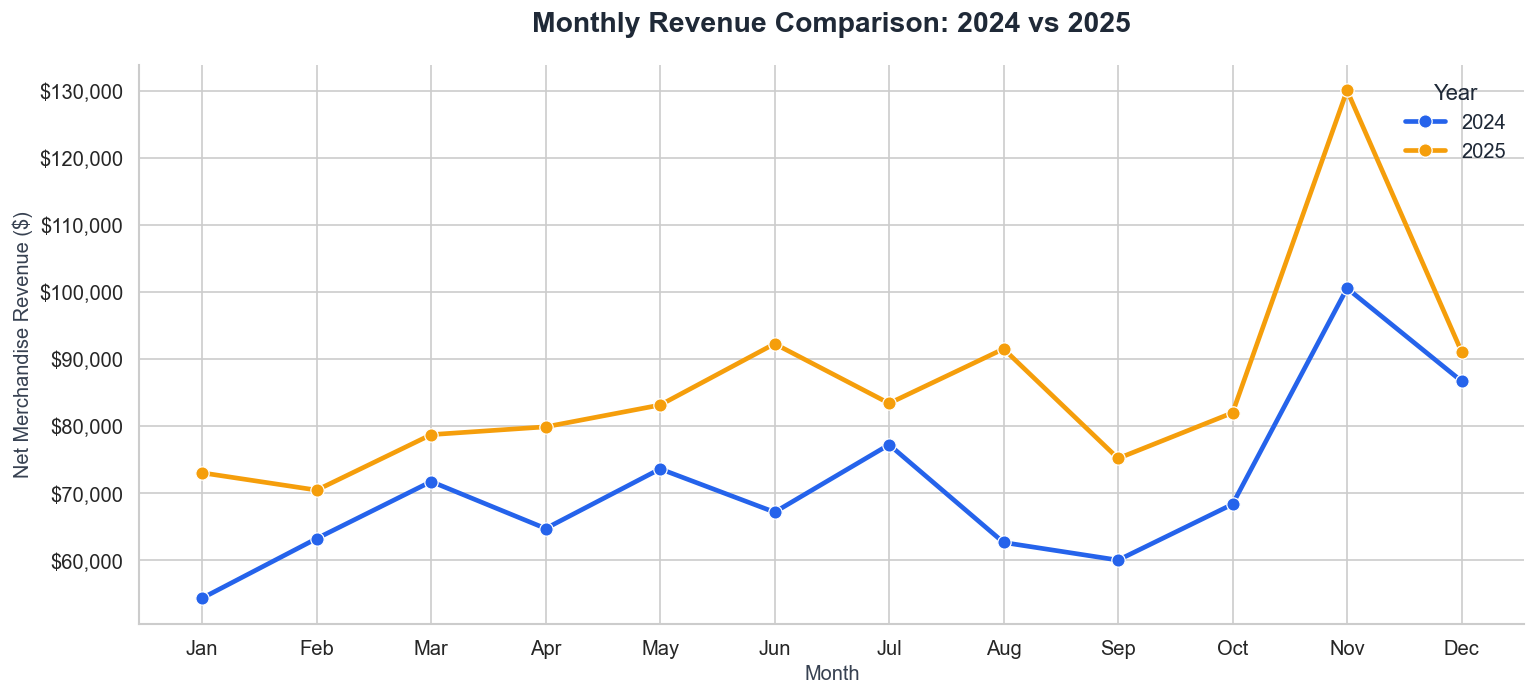

In [55]:
# Calculate monthly revenue by year

monthly_chart = (
    sales_df.groupby(["year", "month"])["net_amount"]
    .sum()
    .reset_index()
)

# Create chart
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_chart,
    x="month",
    y="net_amount",
    hue="year",
    marker="o",
    linewidth=2.8,
    markersize=8,
    palette=["#2563EB", "#F59E0B"]
)

plt.title(
    "Monthly Revenue Comparison: 2024 vs 2025",
    fontsize=17,
    pad=20
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Net Merchandise Revenue ($)", fontsize=12)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.legend(
    title="Year",
    frameon=False
)

sns.despine()

plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "01_monthly_revenue_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

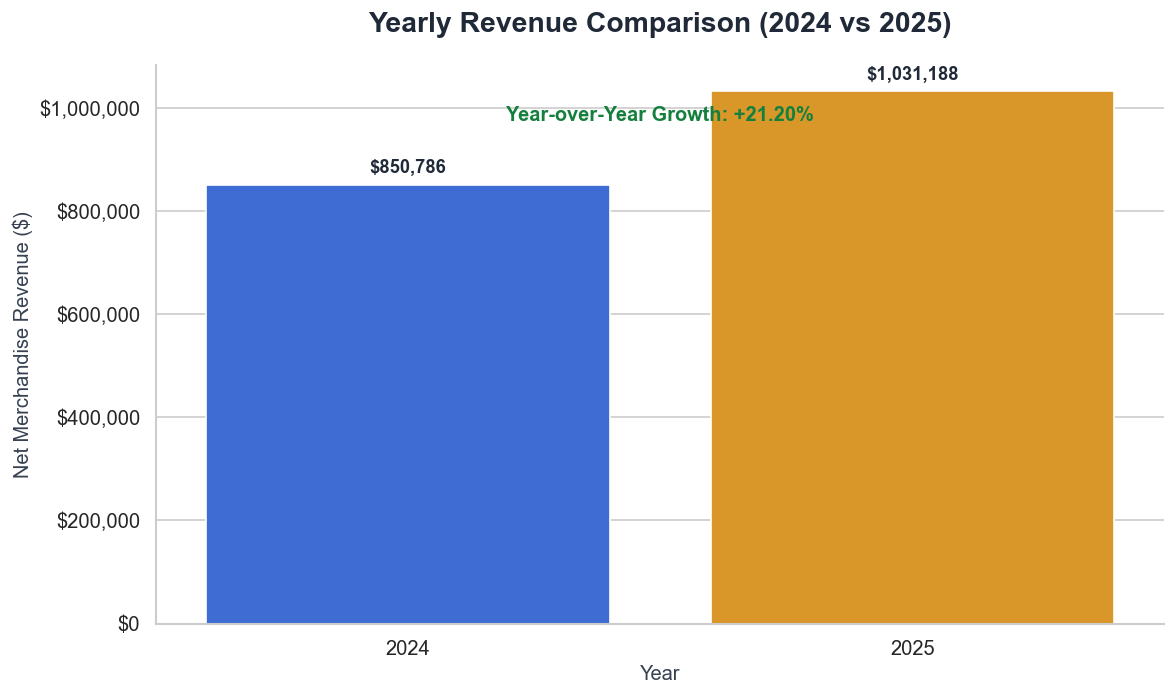

In [56]:
# Calculate yearly revenue

yearly_chart = (
    sales_df.groupby("year")["net_amount"]
    .sum()
    .reset_index()
)

# Calculate year-over-year growth
revenue_2024 = yearly_chart.loc[
    yearly_chart["year"] == 2024, "net_amount"
].iloc[0]

revenue_2025 = yearly_chart.loc[
    yearly_chart["year"] == 2025, "net_amount"
].iloc[0]

growth = ((revenue_2025 - revenue_2024) / revenue_2024) * 100


# Create chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=yearly_chart,
    x="year",
    y="net_amount",
    hue="year",
    palette=["#2563EB", "#F59E0B"],
    legend=False
)

# Add revenue labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"${bar.get_height():,.0f}" for bar in container],
        padding=5,
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Yearly Revenue Comparison (2024 vs 2025)",
    fontsize=17,
    pad=20
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Net Merchandise Revenue ($)", fontsize=12)

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

# Growth annotation
plt.text(
    0.5, 0.90,
    f"Year-over-Year Growth: +{growth:.2f}%",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#15803D"
)

sns.despine()
plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "02_yearly_revenue_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

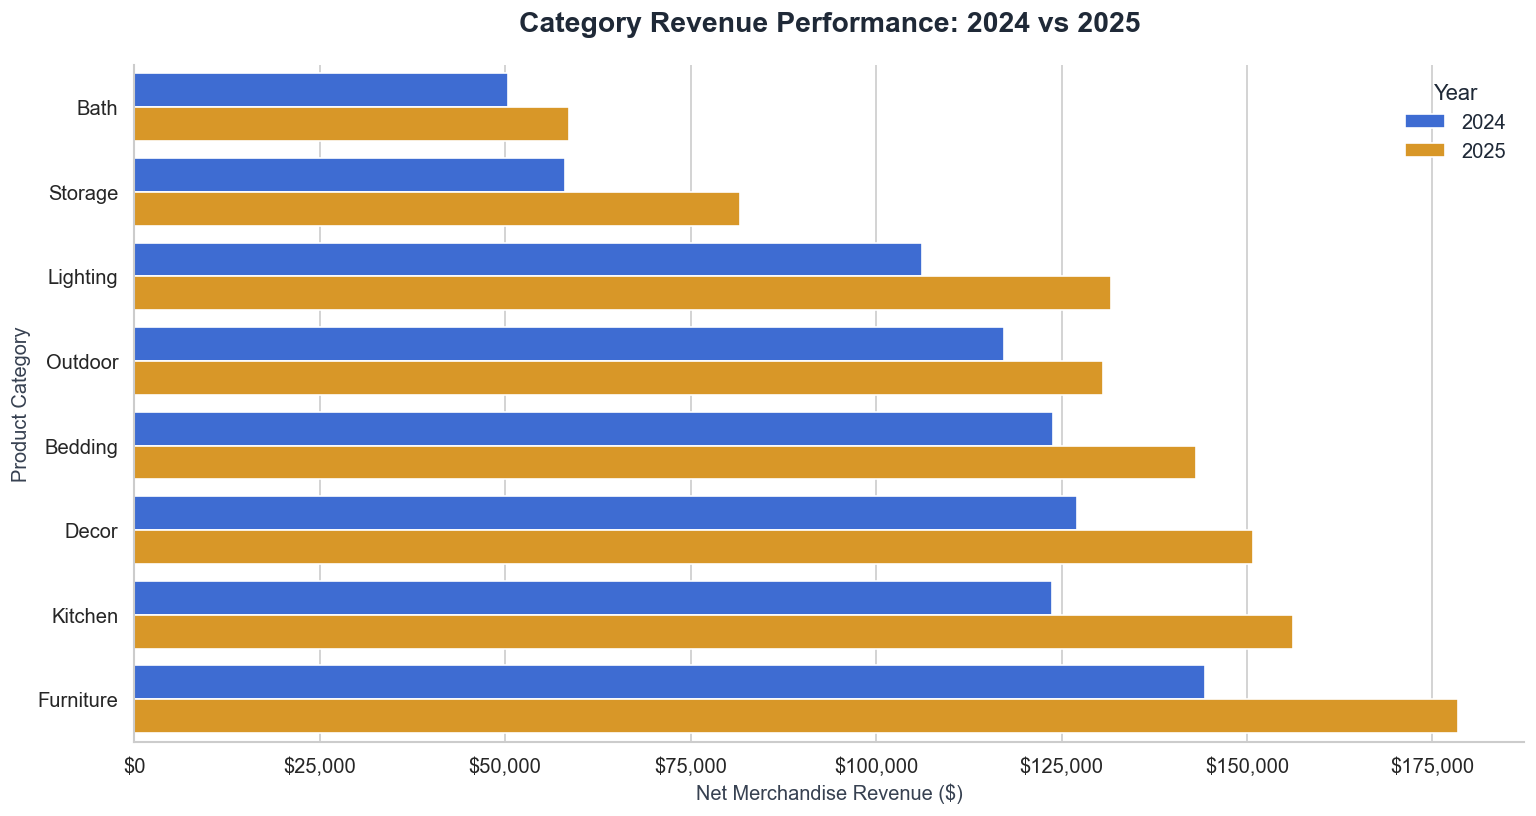

In [57]:
# Calculate category revenue by year

category_chart = (
    sales_df.groupby(["category", "year"])["net_amount"]
    .sum()
    .reset_index()
)

# Sort categories by total revenue
category_order = (
    category_chart.groupby("category")["net_amount"]
    .sum()
    .sort_values(ascending=True)
    .index
)

# Create chart
plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=category_chart,
    y="category",
    x="net_amount",
    hue="year",
    order=category_order,
    palette=["#2563EB", "#F59E0B"]
)

plt.title(
    "Category Revenue Performance: 2024 vs 2025",
    fontsize=17,
    pad=20
)

plt.xlabel("Net Merchandise Revenue ($)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.legend(
    title="Year",
    frameon=False
)

sns.despine()
plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "03_category_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

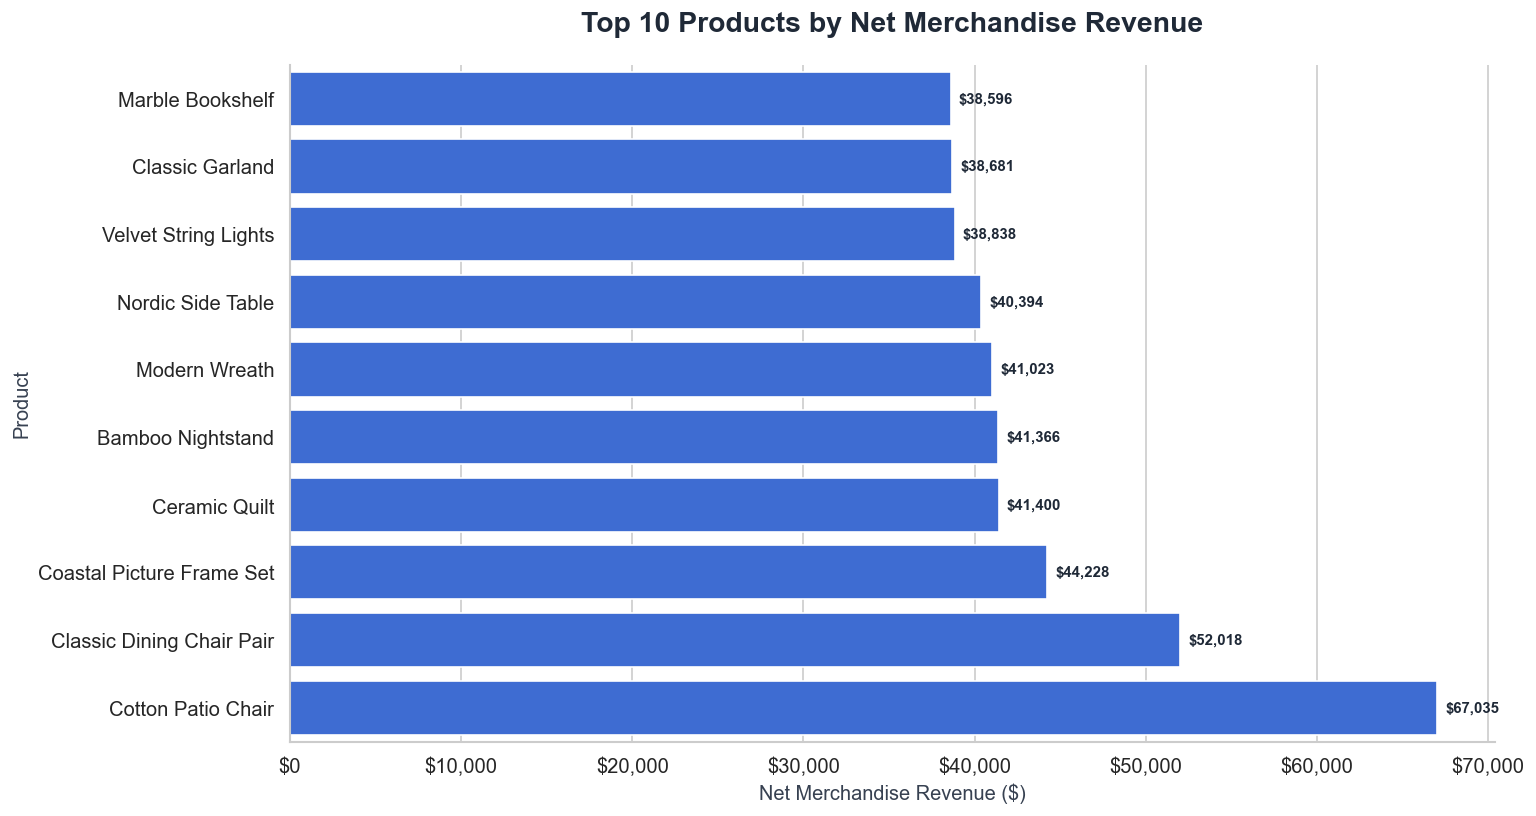

In [58]:
# Calculate revenue by product

product_chart = (
    sales_df.groupby("product_name")["net_amount"]
    .sum()
    .reset_index()
)

# Select top 10 products
top_10_products = (
    product_chart
    .nlargest(10, "net_amount")
    .sort_values("net_amount", ascending=True)
)

# Create chart
plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_10_products,
    y="product_name",
    x="net_amount",
    color="#2563EB"
)

# Add revenue labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"${bar.get_width():,.0f}" for bar in container],
        padding=5,
        fontsize=9,
        fontweight="bold"
    )

plt.title(
    "Top 10 Products by Net Merchandise Revenue",
    fontsize=17,
    pad=20
)

plt.xlabel("Net Merchandise Revenue ($)", fontsize=12)
plt.ylabel("Product", fontsize=12)

ax.xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

sns.despine()
plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "04_top_10_products.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

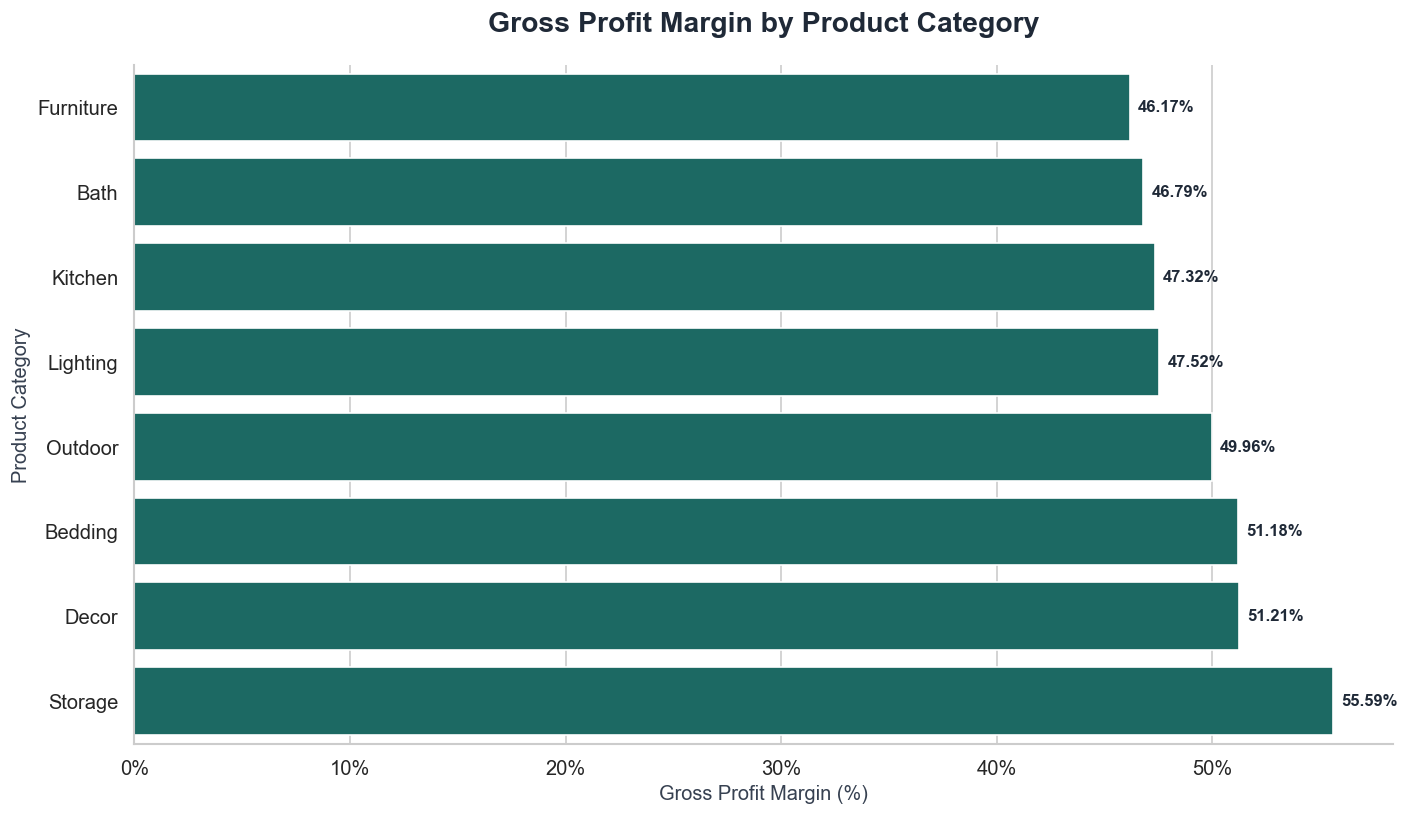

In [59]:
# Calculate gross profit by category

category_profit_chart = (
    sales_df.groupby("category")
    .agg(
        Net_Revenue=("net_amount", "sum"),
        Total_Product_Cost=("total_product_cost", "sum"),
        Gross_Profit=("gross_profit", "sum")
    )
    .reset_index()
)

# Calculate gross profit margin
category_profit_chart["Gross_Profit_Margin"] = (
    category_profit_chart["Gross_Profit"] /
    category_profit_chart["Net_Revenue"]
) * 100

# Sort categories by profit margin
category_profit_chart = (
    category_profit_chart
    .sort_values("Gross_Profit_Margin", ascending=True)
)

# Create chart
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=category_profit_chart,
    y="category",
    x="Gross_Profit_Margin",
    color="#0F766E"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_width():.2f}%" for bar in container],
        padding=5,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Gross Profit Margin by Product Category",
    fontsize=17,
    pad=20
)

plt.xlabel("Gross Profit Margin (%)", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

ax.xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)

sns.despine()
plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "05_category_profit_margin.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

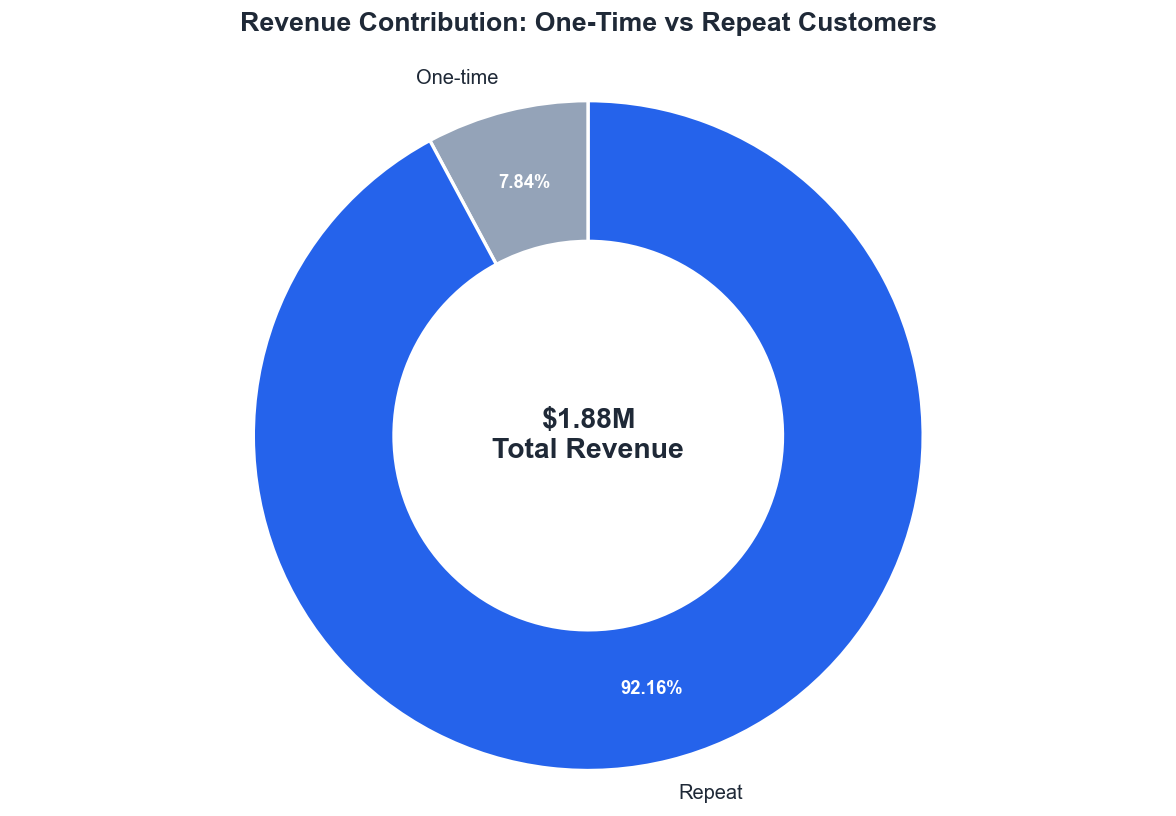

In [60]:
# Prepare customer revenue data

customer_chart = (
    customer_type_analysis
    .set_index("Customer_Type")
    .loc[["One-time", "Repeat"]]
    .reset_index()
)

# Chart data
labels = customer_chart["Customer_Type"]
revenue = customer_chart["Net_Revenue"]

# Professional colours
colors = ["#94A3B8", "#2563EB"]

# Create donut chart
fig, ax = plt.subplots(figsize=(10, 7))

wedges, texts, autotexts = ax.pie(
    revenue,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.42,
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 12
    }
)

# Format percentage labels
for autotext in autotexts:
    autotext.set_fontweight("bold")
    autotext.set_color("white")
    autotext.set_fontsize(11)

# Centre text
ax.text(
    0, 0,
    "$1.88M\nTotal Revenue",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
    color="#1F2937"
)

plt.title(
    "Revenue Contribution: One-Time vs Repeat Customers",
    fontsize=16,
    fontweight="bold",
    pad=22
)

ax.axis("equal")

plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(output_dir, "06_customer_revenue_contribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()